# Indian E-Commerce Customer Segmentation — Production Analysis

This notebook analyzes the outputs produced by the production pipeline:

1. `src.ingest` loads the raw e-commerce CSV files into the database.
2. `src.train` builds customer-level features and trains K-Means.
3. This notebook reads the resulting customer features, segmentation results, and model-selection metrics.

**Important:** this production version works with customer-level data. It does not expect the legacy `merged_orders_cleaned.csv` transaction file.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(r"D:\RUSHII\project resume\Indian_Ecommerce_Customer_Segmentation_PRODUCTION")

FEATURES_PATH = ROOT / "data" / "processed" / "customer_features.csv"
SEGMENTS_PATH = ROOT / "reports" / "customer_segments.csv"
METRICS_PATH = ROOT / "reports" / "cluster_model_metrics.csv"

print("Project root:", ROOT)
print("Features exists:", FEATURES_PATH.exists())
print("Segments exists:", SEGMENTS_PATH.exists())
print("Metrics exists:", METRICS_PATH.exists())

features = pd.read_csv(FEATURES_PATH)
segments = pd.read_csv(SEGMENTS_PATH)
metrics = pd.read_csv(METRICS_PATH)

features["last_order"] = pd.to_datetime(
    features["last_order"],
    errors="coerce"
)

print("Customers:", len(features))
print("Segments:", len(segments))
print("Metrics:", len(metrics))

Project root: D:\RUSHII\project resume\Indian_Ecommerce_Customer_Segmentation_PRODUCTION
Features exists: True
Segments exists: True
Metrics exists: True
Customers: 332
Segments: 332
Metrics: 7


## 1. Quick data quality check

The production dataset is customer-level, so we check missing values, duplicate customer IDs, and the last-order date range.


In [2]:
print("Customer feature columns:")
print(features.columns.tolist())

print("\nSegmentation columns:")
print(segments.columns.tolist())


Customer feature columns:
['customer_id', 'customer_name', 'last_order', 'frequency', 'monetary', 'profit', 'quantity', 'states', 'categories', 'recency', 'avg_order_value', 'profit_margin_pct']

Segmentation columns:
['customer_id', 'customer_name', 'last_order', 'frequency', 'monetary', 'profit', 'quantity', 'states', 'categories', 'recency', 'avg_order_value', 'profit_margin_pct', 'cluster', 'R_score', 'F_score', 'M_score', 'rfm_segment']


In [3]:
# Check missing values in the main customer-level fields
quality_columns = [
    "customer_id",
    "customer_name",
    "last_order",
    "frequency",
    "monetary",
    "profit",
    "quantity",
    "recency",
    "avg_order_value",
    "profit_margin_pct",
]
quality_columns = [c for c in quality_columns if c in features.columns]

print("Missing values:")
display(features[quality_columns].isna().sum().to_frame("missing_values"))

print("Duplicate customer IDs:", features["customer_id"].duplicated().sum())

if features["last_order"].notna().any():
    print(
        "Last-order date range:",
        features["last_order"].min().date(),
        "to",
        features["last_order"].max().date(),
    )

print("Unique customers:", features["customer_id"].nunique())


Missing values:


,missing_values
customer_id,0
customer_name,0
last_order,0
frequency,0
monetary,0
profit,0
quantity,0
recency,0
avg_order_value,0
profit_margin_pct,0


Duplicate customer IDs: 0
Last-order date range: 2018-05-10 to 2019-03-31
Unique customers: 332


## 2. Customer value overview

The production feature table contains customer-level revenue (`monetary`) and profit. Instead of the legacy transaction-level monthly trend, we summarize customer value directly.


In [4]:
value_summary = features[["monetary", "profit", "frequency", "recency"]].describe().round(2)

display(value_summary)

print(f"Total customer revenue: {features['monetary'].sum():,.2f}")
print(f"Total customer profit: {features['profit'].sum():,.2f}")
print(f"Average customer revenue: {features['monetary'].mean():,.2f}")
print(f"Average frequency: {features['frequency'].mean():,.2f}")


,monetary,profit,frequency,recency
count,332.00,332.00,332.00,332.00
mean,1299.70,72.15,1.51,130.59
std,1577.29,398.76,0.88,89.82
min,11.00,-1836.00,1.00,1.00
25%,178.50,-48.50,1.00,59.75
50%,764.50,30.00,1.00,118.00
75%,1716.50,202.50,2.00,198.00
max,9177.00,1970.00,6.00,326.00


Total customer revenue: 431,502.00
Total customer profit: 23,955.00
Average customer revenue: 1,299.70
Average frequency: 1.51


## 3. Customer value distribution

Look at the distribution of customer revenue and purchase frequency before relying only on averages.


In [5]:
print("Top 10 customers by revenue:")
display(
    features.nlargest(10, "monetary")[
        ["customer_id", "customer_name", "monetary", "profit", "frequency", "recency"]
    ]
)


Top 10 customers by revenue:


,customer_id,customer_name,monetary,profit,frequency,recency
285,d92101af92d9555c,Yaanvi,9177,488,2,22
14,0962ef04822f8ca5,Pooja,9030,-269,5,36
92,42b5bf6a3fa51849,Abhishek,8135,1314,5,115
270,cf199fca37cf1c6d,Surabhi,6889,412,4,202
245,bc498711f13df2fd,Soumya,6869,894,3,70
197,95533be22529ee0e,Harshal,6026,864,1,57
218,a1fd973ae59aace7,Priyanka,5762,1340,4,16
272,cfbff47427fb6860,Shruti,5750,485,4,14
145,69975c4c0cdb7973,Abhijeet,5691,1562,2,142
74,38ff0b7c7cc0761a,Sarita,5449,1265,3,5


In [6]:
top10_share = (
    features.nlargest(10, "monetary")["monetary"].sum()
    / features["monetary"].sum()
    * 100
)

print(f"Top 10 customers contribute {top10_share:.1f}% of historical customer revenue.")


Top 10 customers contribute 15.9% of historical customer revenue.


## 4. RFM / strategic segmentation

The production model produces customer segments. We use the actual columns present in the generated segmentation file rather than relying on the legacy notebook's `rfm_segment` and `CustomerName` columns.


In [7]:
# Inspect the available segment/persona column
candidate_segment_columns = [
    "strategic_persona",
    "rfm_segment",
    "segment",
    "cluster",
    "assigned_cluster",
]

segment_column = next(
    (c for c in candidate_segment_columns if c in segments.columns),
    None,
)

if segment_column is None:
    print("No recognized segment column found.")
    print("Available columns:", segments.columns.tolist())
else:
    print(f"Using segment column: {segment_column}")

    segment_summary = (
        segments.groupby(segment_column, as_index=False)
        .size()
        .rename(columns={"size": "customers"})
        .sort_values("customers", ascending=False)
    )

    display(segment_summary)


Using segment column: rfm_segment


,rfm_segment,customers
0,Champions,79
2,Inactive / Low Engagement,74
1,High Value - At Risk,68
3,Loyal / Active,66
4,Potential Growth,45


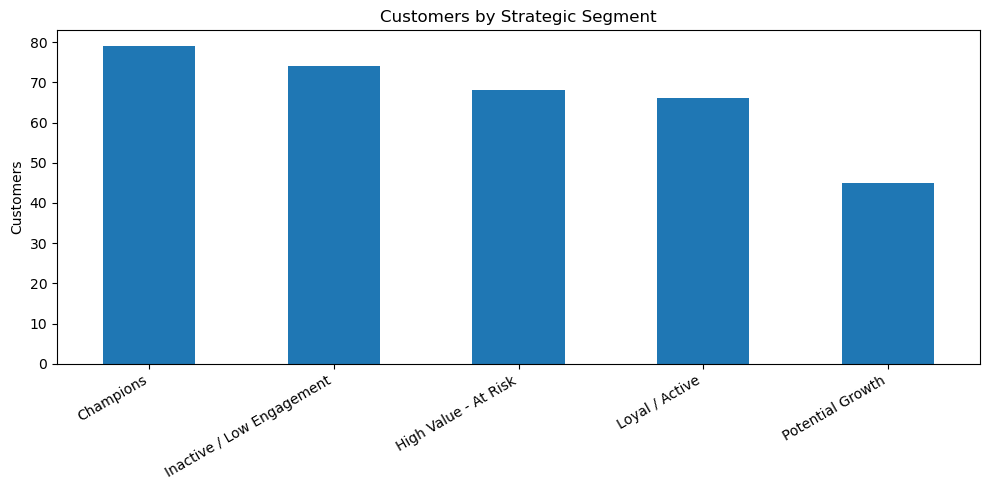

In [8]:
if segment_column is not None:
    segment_summary.plot(
        kind="bar",
        x=segment_column,
        y="customers",
        figsize=(10, 5),
        legend=False,
    )
    plt.title("Customers by Strategic Segment")
    plt.xlabel("")
    plt.ylabel("Customers")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


## 5. K-Means model selection

The production training pipeline evaluates multiple values of K and saves the model-selection metrics in `reports/cluster_model_metrics.csv`.


In [9]:
display(metrics.round(3))


,k,inertia,silhouette_score
0,2,552.511,0.468
1,3,398.403,0.376
2,4,284.911,0.415
3,5,230.310,0.437
4,6,199.065,0.424
5,7,175.809,0.386
6,8,152.248,0.402


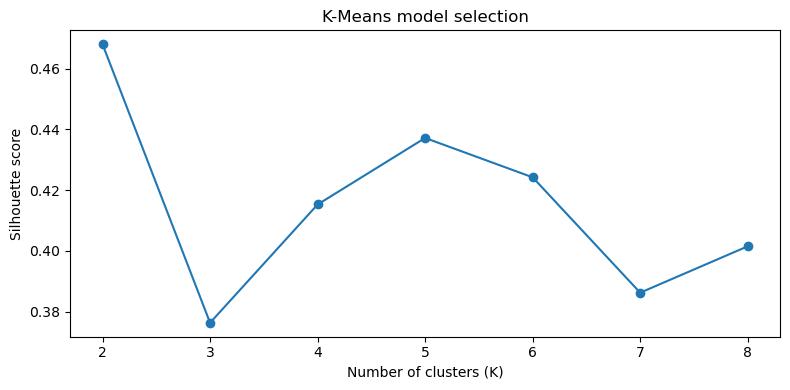

Best silhouette score: 0.468 at K=2


In [10]:
if {"k", "silhouette_score"}.issubset(metrics.columns):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(metrics["k"], metrics["silhouette_score"], marker="o")
    ax.set_xlabel("Number of clusters (K)")
    ax.set_ylabel("Silhouette score")
    ax.set_title("K-Means model selection")
    plt.tight_layout()
    plt.show()

    best_row = metrics.loc[metrics["silhouette_score"].idxmax()]
    print(
        f"Best silhouette score: {best_row['silhouette_score']:.3f} "
        f"at K={int(best_row['k'])}"
    )
else:
    print("Expected columns 'k' and 'silhouette_score' were not found.")


## 6. Business interpretation

The final step is to turn clusters/personas into business actions.

The production prediction pipeline returns an `assigned_cluster` and a `strategic_persona`. Cluster numbers themselves are technical labels; the business meaning should come from the customer behavior represented by each group.

Useful actions include:

- **Active / valuable customers:** retention, loyalty benefits, and cross-sell opportunities.
- **High-recency-risk customers:** re-engagement campaigns and targeted offers.
- **Frequent customers:** loyalty programs and repeat-purchase incentives.
- **Lower-value customers:** cost-efficient campaigns and product recommendations.

Always validate the exact persona definitions against the production pipeline before presenting them as fixed business rules.


In [11]:
# Optional: combine customer features with segmentation results for a single analysis table
if "customer_id" in segments.columns and "customer_id" in features.columns:
    analysis = features.merge(
        segments,
        on="customer_id",
        how="left",
        suffixes=("", "_segment"),
    )
    print("Combined analysis rows:", len(analysis))
    display(analysis.head())
else:
    analysis = segments.copy()
    print("Could not merge on customer_id; using segmentation results directly.")


Combined analysis rows: 332


,customer_id,customer_name,last_order,frequency,monetary,profit,quantity,states,categories,recency,...,states_segment,categories_segment,recency_segment,avg_order_value_segment,profit_margin_pct_segment,cluster,R_score,F_score,M_score,rfm_segment
0,000e02e40e441be7,Anita,2019-03-25,3,561,-54,17,1,3,7,...,1,3,7,187.000000,-9.625668,1,4,4,2,Loyal / Active
1,003a626c12936f2b,Noopur,2018-06-21,1,1607,-207,17,1,2,284,...,1,2,284,1607.000000,-12.881145,0,1,1,3,High Value - At Risk
2,00bbf5ef9b6831e9,Hitika,2019-03-31,3,1160,285,17,1,2,1,...,1,2,1,386.666667,24.568966,1,4,4,3,Champions
3,00d8aec08899f11f,Aayush,2018-11-15,1,556,-38,18,1,2,137,...,1,2,137,556.000000,-6.834532,0,2,1,2,Inactive / Low Engagement
4,021fb044d1c216bc,Sanjay,2019-03-02,3,517,-61,8,2,2,30,...,2,2,30,172.333333,-11.798839,1,4,4,2,Loyal / Active
